In [1]:
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import sys


range(0, 102)


/var/folders/lm/1s7yhzbn56l3gt6dp_gzhtgc0000gn/T/ipykernel_42233/322929335.py:149: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


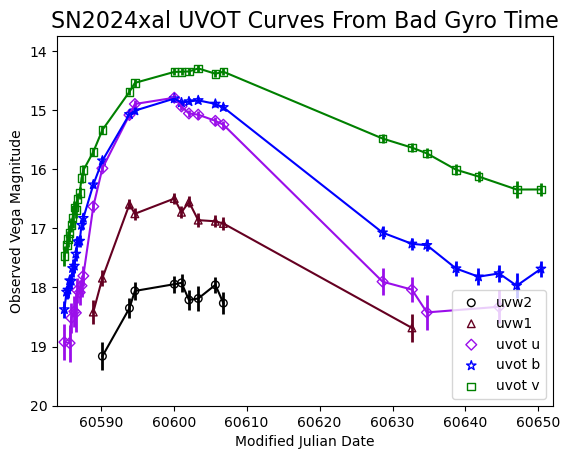

In [6]:
snname = "SN2024xal"
#os.chdir(os.path.expanduser('~/Dropbox/SN/SOUSA/data'))

path = "/Volumes/T7/SwiftSNarchive2020s/"
version = "25.0"
filename =  path+snname+"/"+snname + '_uvotB'+version+'.dat'
sousasavename = '/Users/supernova/Desktop/SN/github/SOUSA/lcplots/'+snname + '_pylightcurve.jpg'
savename = snname + '_pylightcurve.jpg'
savename = sousasavename
data = open(filename, 'r')



#Initializing lists needed to plot the different filters separately
uvw2mjd = []
uvw2mag = []
uvw2magerr = []
uvm2mjd = []
uvm2mag = []
uvm2magerr = []
uvw1mjd = []
uvw1mag = []
uvw1magerr = []
umjd = []
umag = []
umagerr = []
bmjd = []
bmag = []
bmagerr = []
vmjd = []
vmag = []
vmagerr = []


#Reading the data in from the file
lines= np.genfromtxt(data, dtype=[('filter','S4'),('mjd',float),('mag',float),('magerr',float)], usecols = (0,1,2,3), unpack=True, autostrip=True)


mjd = np.atleast_1d(lines[1])
mag = np.atleast_1d(lines[2])
magerr = np.atleast_1d(lines[3])
filters = np.atleast_1d(lines[0])

#print(filters)
#print(filters.size)

#I needed to get rid of the NULL values in the ...15.1.dat files, so the next several lines are to make sure the 
#program doesn't shut down because of them
filterslist = []
mjdlist  = []
maglist = []
magerrlist = []


for i in range(filters.size):
    #print(i)
    #print(mag[i])
    if not np.isnan(mag[i]):
        filterslist.append(filters[i])
        maglist.append(mag[i])
        mjdlist.append(mjd[i])
        magerrlist.append(magerr[i])
filters = np.array(filterslist)
mjd = np.array(mjdlist)
mag = np.array(maglist)
magerr = np.array(magerrlist)	

print(range(len(filterslist)))

#breaking up the filters, mjd, mag, and magerr arrays into separate arrays to make plotting easier
for i in range(filters.size):
	if filterslist[i] == b'UVW2':
		uvw2mjd.append(mjdlist[i])
		uvw2mag.append(maglist[i])
		uvw2magerr.append(magerrlist[i])
	if filterslist[i] == b'UVM2':
		uvm2mjd.append(mjdlist[i])
		uvm2mag.append(maglist[i])
		uvm2magerr.append(magerrlist[i])
	if filterslist[i] == b'UVW1':
		uvw1mjd.append(mjdlist[i])
		uvw1mag.append(maglist[i])
		uvw1magerr.append(magerrlist[i])
	if filterslist[i] == b'U':
		umjd.append(mjdlist[i])
		umag.append(maglist[i])
		umagerr.append(magerrlist[i])
	if filterslist[i] == b'B':
		bmjd.append(mjdlist[i])
		bmag.append(maglist[i])
		bmagerr.append(magerrlist[i])
	if filterslist[i] == b'V':
		vmjd.append(mjdlist[i])
		vmag.append(maglist[i])
		vmagerr.append(magerrlist[i])



##########This begins plotting portion##########
plt.ion() #turns on interactive plotting
fig =plt.figure()
ax = fig.add_subplot(111)
#The next several lines are just to make sure the program doesn't shut down if one of the filters is missing 


if len(uvw2mag) > 0:
	plt.scatter(uvw2mjd, uvw2mag, linestyle='-', linewidth=1,marker='o', facecolors='none', edgecolors='xkcd:black', s=30, label='uvw2', color = 'xkcd:black')
	plt.errorbar(uvw2mjd, uvw2mag, yerr=uvw2magerr, elinewidth=2, capthick = 2, color = 'xkcd:black')
if len(uvm2mag) > 0:
	plt.scatter(uvm2mjd, uvm2mag, linestyle='-', linewidth=1,marker='v',facecolors='none', edgecolors='r', s=30, label='uvm2', color= 'r')
	plt.errorbar(uvm2mjd, uvm2mag, yerr=uvm2magerr, elinewidth=2, capthick = 2, color='r')
if len(uvw1mag) > 0:
	plt.scatter(uvw1mjd, uvw1mag, linestyle='-', linewidth=1,marker='^', facecolors='none', edgecolors='xkcd:maroon', s=30, label='uvw1', color= 'xkcd:maroon')
	plt.errorbar(uvw1mjd, uvw1mag, yerr=uvw1magerr, elinewidth=2, capthick = 2, color='xkcd:maroon')
if len(umag) > 0:
	plt.scatter(umjd, umag, linestyle='-', linewidth=1,marker='D',facecolors='none', edgecolors='xkcd:violet', s=30, label='uvot u', color= 'xkcd:violet')
	plt.errorbar(umjd, umag, yerr=umagerr, elinewidth=2, capthick = 2, color='xkcd:violet')
if len(bmag) > 0:
	plt.scatter(bmjd, bmag, linestyle='-', linewidth=1,marker='*',facecolors='none', edgecolors='b', s=50, label='uvot b', color= 'b')
	plt.errorbar(bmjd, bmag, yerr=bmagerr, elinewidth=2, capthick = 2, color='b')
if len(vmag) > 0:
	plt.scatter(vmjd, vmag, linestyle='-', linewidth=1,marker='s',facecolors='none', edgecolors='g', s=30, label='uvot v', color= 'g')
	plt.errorbar(vmjd, vmag, yerr=vmagerr, elinewidth=2, capthick = 2, color='g')


ax.legend(loc='lower right')
#If you have labels specified in the plotting commands above, all you have to do is add this line to make a legend
#Also, apparently you can set the location to 'best' so it'll place it wherever python thinks it's the best
ax.set_xlabel('Modified Julian Date')

ax.set_ylabel('Observed Vega Magnitude')

ax.set_title(snname+' UVOT Curves From Bad Gyro Time', fontsize = 16)
#plt.title('UVOT Light Curves During Bad Gypro Time Period', fontsize = 12) 
#there aren't title and subtitle commands so instead I used suptitle and title to get a makeshift main title and subtitle

ax.axis([int(mjd.min())-1, math.ceil(np.amax(mjd-00.0))+1,math.ceil(np.amax(mag)+np.amax(magerr)), int(mag.min())-0.25])
'''
In order to make the axis format correctly, I used the minimum and maxiumum values for the MJD +/- 1 (in order to give the plots some extra
 space) on the x-axis, and the min and max values for the magnitude. The functions int() and math.ceil() are used to round the numbers to the
 nearest whole number to make the ends of the graph neater.
'''
plt.gca().get_xaxis().get_major_formatter().set_useOffset(False)
#The line above makes sure that the x axis is formatted correctly. The Offset option in matplotlib is automatically activated, so for big
#numbers like the MJD, it cuts it off in a strange way that is awful to look at. This makes it readable.

fig.savefig(savename) #you can uncomment this line if you want to save the figure to the SN file

fig.show()